# Prediction of BS incoming in 90 s

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from Prediction.extract_data import *
import json

## Extract the variables 

### Load dictionnary for BS data

In [2]:
with open('Prediction/Dictionnary.json', 'r') as json_file:
    D_BS = json.load(json_file)

### Load for OK data

In [3]:
with open('Prediction/Ok_data.json', 'r') as file:
    D_OK = json.load(file)

### Extract data

In [ ]:
# 1 label: IES in less than 90 s
var1 = get_label_1_data(D_BS, prior_t = 90, delta_t = 240)
# 0 label: no IES in less than 90 s
var0 = get_label_0_data(D_OK, delta_t = 240)

rec_20240321_085300.mat
len_input_Data: 158848
len_variable: 231
len_smoothing filter:  36
rec_20240125_094414.mat
len_input_Data: 283520
len_variable: 425


c:\Users\holcman\Desktop\code\data prediction\Spindles\get_spindle_type.py:205: RuntimeWarning: divide by zero encountered in scalar divide
  ratio = np.sum(mask_slow) / np.sum(mask_fast)


len_smoothing filter:  36
rec_20240321_131557.mat
len_input_Data: 353280
len_variable: 534
len_smoothing filter:  36
rec_20240411_122350.mat
len_input_Data: 230912
len_variable: 343
len_smoothing filter:  36
rec_20240411_103638.mat
len_input_Data: 246400
len_variable: 367
len_smoothing filter:  36
rec_20240411_090403.mat
len_input_Data: 211584
len_variable: 313
len_smoothing filter:  36
eeg_producer__10_10_2024__10_44_13.npy
len_input_Data: 81920
len_variable: 110
len_smoothing filter:  36
eeg_producer__17_10_2024__09_04_07.npy
len_input_Data: 505856
len_variable: 773
len_smoothing filter:  36
d_AA68
no ground check detected


C:\Users\holcman\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pywt\_multilevel.py:43: UserWarning: Level value of 4 is too high: all coefficients will experience boundary effects.
  warnings.warn(


len_input_Data: 382376
len_variable: 1196
len_smoothing filter:  36
d_AB56
no ground check detected
len_input_Data: 593792
len_variable: 1868
len_smoothing filter:  36
d_AW67
no ground check detected
len_input_Data: 559197
len_variable: 1758
len_smoothing filter:  36
d_BE74
no ground check detected
len_input_Data: 104416
len_variable: 314
len_smoothing filter:  36
d_BN49
len_input_Data: 98303
len_variable: 295
len_smoothing filter:  36
d_BN65
no ground check detected
len_input_Data: 128551
len_variable: 391
len_smoothing filter:  36
d_CC65
no ground check detected
len_input_Data: 154261
len_variable: 472
len_smoothing filter:  36
d_CV71
len_input_Data: 780570
len_variable: 2460
len_smoothing filter:  36
d_EA68
len_input_Data: 284702
len_variable: 886
len_smoothing filter:  36
d_FA68
no ground check detected
len_input_Data: 98303
len_variable: 295
len_smoothing filter:  36
d_LC82
no ground check detected
len_input_Data: 71522
len_variable: 210
len_smoothing filter:  36
d_LM67
no ground 

C:\Users\holcman\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\scipy\io\matlab\_mio.py:235: MatReadWarning: Duplicate variable name "None" in stream - replacing previous with new
Considerscipy.io.matlab.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)


len_input_Data: 832000
len_variable: 1282
len_smoothing filter:  36
rec_20240111_090304
len_input_Data: 896000
len_variable: 1382
len_smoothing filter:  36
rec_20240111_115315
len_input_Data: 217600
len_variable: 322
len_smoothing filter:  36
rec_20240111_115315
len_input_Data: 403200
len_variable: 612
len_smoothing filter:  36
rec_20240118_115349
len_input_Data: 422400
len_variable: 642
len_smoothing filter:  36
rec_20240118_115349
len_input_Data: 473600
len_variable: 722
len_smoothing filter:  36
rec_20240125_110611
len_input_Data: 76800
len_variable: 102
len_smoothing filter:  36
rec_20240125_110611
len_input_Data: 76800
len_variable: 102
len_smoothing filter:  36
rec_20240125_115738
len_input_Data: 311040
len_variable: 468
len_smoothing filter:  36
rec_20240201_110448
len_input_Data: 51200
len_variable: 62
len_smoothing filter:  36
rec_20240201_110448
len_input_Data: 106240
len_variable: 148
len_smoothing filter:  36
rec_20240201_110448
len_input_Data: 217600
len_variable: 322
len_

## get variables for the classifier

In [5]:
res0=[]
res1=[]
fs=128

# list for selected samples for label 1
L_BS = [35,33,29,27,25,23,21,19,18,17,15,12,11,8,7,5,4,3,2,1]

for i in L_BS:

    a1=np.zeros((10,2))

    N=len(var1[i-1][0])
    t1=np.linspace(0,N*5,N)

    for k in range(10):

        popt=np.polyfit(t1,var1[i-1][k],1)
        a1[k,0]=popt[0]
        a1[k,1]=popt[1]
    
    res1.append(a1)

for i in range(len(var0)):

    a0=np.zeros((10,2))

    N=len(var0[i][0])
    t0=np.linspace(0,N*5,N)

    for k in range(10):

        popt=np.polyfit(t0,var0[i][k],1)
        a0[k,0]=popt[0]
        a0[k,1]=popt[1]
    
    res0.append(a0)

res1=np.array(res1)
res0=np.array(res0)

Save data for faster reloading


In [6]:
np.save('res1.npy', res1)
np.save('res0.npy', res0)

### Visualize distributions

In [7]:
import matplotlib.pyplot as plt

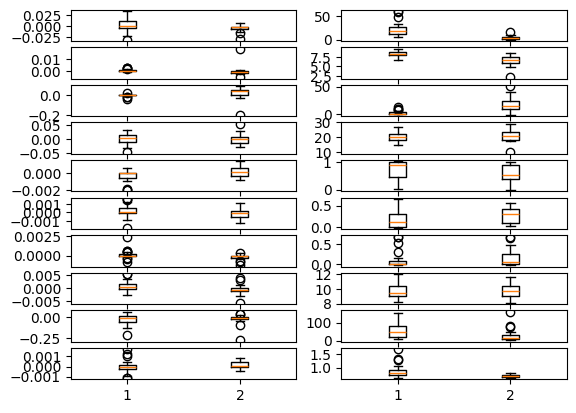

In [8]:
fig,axes = plt.subplots(10,2)
for k in range(10):
    L = [res0[:,k,0], res1[:,k,0]]
    axes[k,0].boxplot(L)
    L = [res0[:,k,1], res1[:,k,1]]
    axes[k,1].boxplot(L)

plt.show()

In [9]:
print(res0)

[[[ 1.26373493e-02  9.30438483e+00]
  [ 9.01926987e-04  7.87218700e+00]
  [-1.85572377e-02  1.37560931e+01]
  [ 5.19459875e-03  2.20225530e+01]
  [-5.61808170e-04  1.16591796e-01]
  [ 4.05488254e-06  2.25258362e-01]
  [ 5.57753287e-04  6.58149842e-01]
  [ 4.46094090e-04  1.20186845e+01]
  [-4.43668573e-02  1.14745025e+02]
  [-8.17039685e-05  6.88768353e-01]]

 [[ 6.18231126e-03  1.57090607e+01]
  [ 4.06336074e-04  8.10999077e+00]
  [-2.87335359e-03  9.60323446e-01]
  [-1.27445161e-02  2.15375332e+01]
  [ 1.37863786e-04  7.20687161e-01]
  [-4.40106517e-05  2.62507930e-01]
  [-9.38531338e-05  1.68049089e-02]
  [ 1.33723725e-03  1.02647978e+01]
  [ 6.27168001e-02  6.48192589e+01]
  [ 4.83335670e-05  9.00657756e-01]]

 [[-2.18789593e-03  1.42697565e+01]
  [-1.93133467e-04  7.86200735e+00]
  [ 3.31054963e-03 -9.18400749e-02]
  [ 1.33981608e-02  1.71862004e+01]
  [-5.11083979e-04  3.36047697e-01]
  [ 6.08092663e-04  5.55158994e-01]
  [-9.70086842e-05  1.08793309e-01]
  [ 2.85494176e-04  1.07

In [10]:
print(res1)

[[[-7.58478965e-04  1.36610836e+00]
  [-1.87712003e-04  5.93183175e+00]
  [ 5.59796777e-02  2.14951412e+01]
  [-5.67950763e-03  2.20573699e+01]
  [-3.48587011e-04  9.76556339e-01]
  [ 3.48587011e-04  2.34436607e-02]
  [ 0.00000000e+00  0.00000000e+00]
  [ 1.06243468e-03  8.75883667e+00]
  [-1.01691508e-02  6.54281186e+00]
  [ 1.67358158e-04  6.29026458e-01]]

 [[-5.59402600e-03  4.38901940e+00]
  [-8.20799413e-04  7.46429651e+00]
  [ 6.18066390e-02  1.42500785e+01]
  [-1.25110775e-02  1.73856118e+01]
  [ 1.41937142e-03  1.18909334e-01]
  [-9.59049912e-04  5.52409604e-01]
  [-4.60321503e-04  3.28681062e-01]
  [-2.82008165e-03  1.08840475e+01]
  [-7.58788951e-03  8.07802106e+00]
  [ 5.29980350e-04  6.99347317e-01]]

 [[-2.76040537e-03  2.28736155e+00]
  [-1.47488401e-03  6.77555446e+00]
  [ 4.33516772e-03  2.92456730e+01]
  [-1.98678156e-02  2.52938646e+01]
  [ 6.31951725e-04  6.89250804e-01]
  [-4.98090440e-04  2.42092164e-01]
  [-1.33861285e-04  6.86570320e-02]
  [-8.94470633e-04  9.54

Take only delta parameters (to delete to have full parameters)

In [11]:
# res0 = res0[:,-2:,:]
# res1 = res1[:,-2:,:]

In [12]:
# print(res0)

In [13]:
# print(res1)

### Train classifier

In [14]:
# import lightgbm as lgb

In [15]:
# #'''
# #for only delta parameters
# X = []
# for res in res0:
#     X.append(np.reshape(res,4))

# for res in res1:
#     X.append(np.reshape(res,4))

# y = np.array([0]*len(var0) + [1]*len(L_BS)) 
# #'''

In [16]:
X = []
for res in res0:
    X.append(np.reshape(res,20))

for res in res1:
    X.append(np.reshape(res,20))

y = np.array([0]*len(var0) + [1]*len(L_BS)) 

In [17]:
# # Splitting dataset into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)
# X_train = np.array(X_train)
# X_test = np.array(X_test)
# y_train = np.array(y_train)
# y_test = np.array(y_test)
# # Check the shape of the training data (this will help debug any issues with the dataset)
# print(f"Shape of X_train: {X_train.shape}")
# print(f"Shape of y_train: {y_train.shape}")

In [18]:
# from sklearn.model_selection import  GridSearchCV
# from sklearn.metrics import classification_report,confusion_matrix

In [19]:
# # Define the LightGBM classifier
# lgbm_clf = lgb.LGBMClassifier(random_state=42)

# # Define the hyperparameter grid for GridSearchCV
# param_grid = {
#     'num_leaves': [31, 50, 70],
#     'max_depth': [5, 10, 15],
#     'learning_rate': [0.05, 0.1, 0.2],
#     'n_estimators': [100, 200]
# }

# # Set up GridSearchCV with stratified cross-validation
# grid_search = GridSearchCV(estimator=lgbm_clf, param_grid=param_grid, 
#                            cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# # Train the model using GridSearchCV
# grid_search.fit(X_train, y_train)

In [20]:
# # Output the best hyperparameters found by GridSearchCV
# print("Best hyperparameters:", grid_search.best_params_)

# # Predict on the test set
# y_pred = grid_search.best_estimator_.predict(X_test)

# # Evaluate the performance
# print("Classification Report:\n", classification_report(y_test, y_pred))

In [21]:
# import seaborn as sns

In [22]:
# # Confusion Matrix
# cm = confusion_matrix(y_test, y_pred)
# # Convert confusion matrix to percentages
# cm_percentage = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

In [23]:
# print(y_test)

In [24]:
# # Plot confusion matrix using seaborn
# plt.figure(figsize=(6, 5))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
# plt.title('Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

In [25]:


# # Plot confusion matrix using seaborn as percentages
# plt.figure(figsize=(6, 5))
# sns.heatmap(cm_percentage, annot=True, fmt='.2f', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
# plt.title('Confusion Matrix (Percentage)')
# plt.xlabel('Predicted Label')
# plt.ylabel('True Label')
# plt.show()

Fitting 5 folds for each of 54 candidates, totalling 270 fits
[LightGBM] [Info] Number of positive: 14, number of negative: 27
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000266 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 194
[LightGBM] [Info] Number of data points in the train set: 41, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.341463 -> initscore=-0.656780
[LightGBM] [Info] Start training from score -0.656780
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

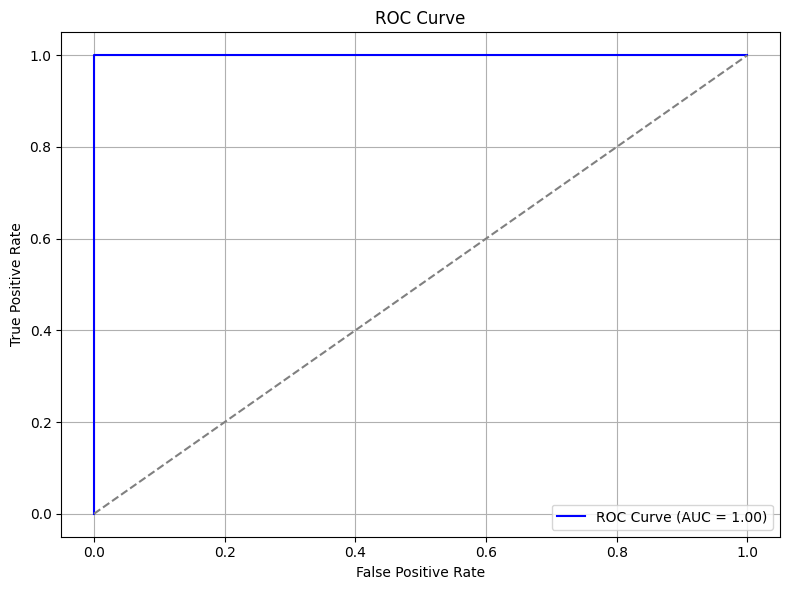

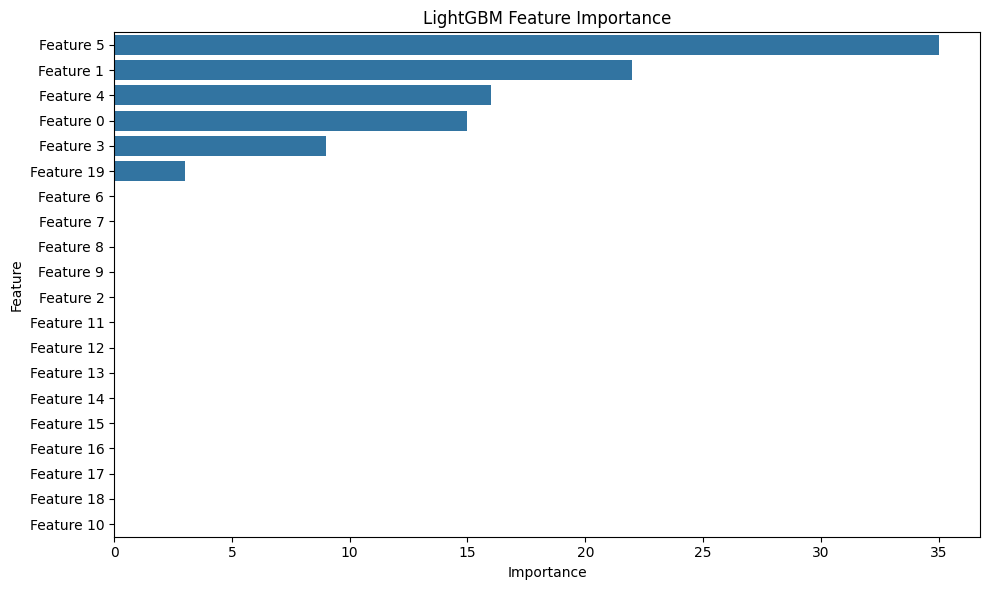

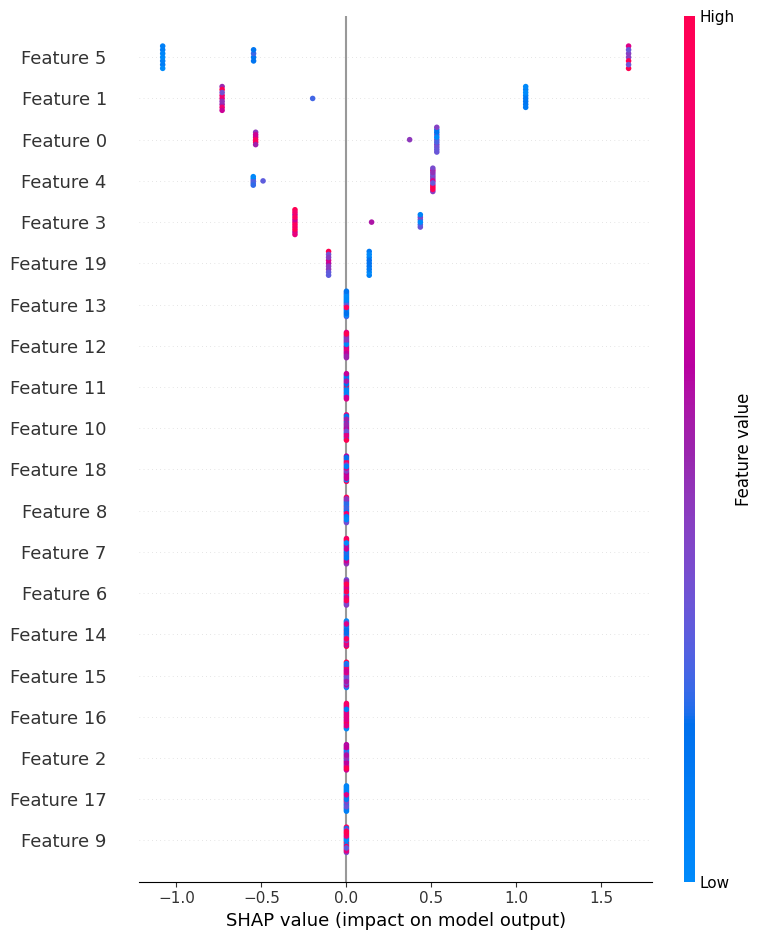

In [ ]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
import pandas as pd
import shap

# Splitting dataset into training and testing sets
X = np.array(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

# Define the LightGBM classifier
lgbm_clf = lgb.LGBMClassifier(random_state=42)

# Define the hyperparameter grid for GridSearchCV
param_grid = {
    'num_leaves': [31, 50, 70],
    'max_depth': [5, 10, 15],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100, 200]
}

# Set up GridSearchCV with stratified cross-validation
grid_search = GridSearchCV(estimator=lgbm_clf, param_grid=param_grid, 
                           cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# Train the model using GridSearchCV
grid_search.fit(X_train, y_train)

# Output the best hyperparameters found by GridSearchCV
print("Best hyperparameters:", grid_search.best_params_)

# Predict on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]  # For ROC AUC

# Classification metrics
print("Classification Report:\n", classification_report(y_test, y_pred))

# Compute and print ROC AUC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

# Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Plot Feature Importance
feature_importance = best_model.feature_importances_

# Handle NumPy array by creating generic feature names
feature_names = [f"Feature {i}" for i in range(X.shape[1])]
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importance})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('LightGBM Feature Importance')
plt.tight_layout()
plt.show()

# Ensure X_test is a NumPy array and use the same feature names
X_test_array = np.array(X_test)

# Create SHAP explainer and compute SHAP values
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test_array)

# SHAP summary plot
shap.summary_plot(shap_values, X_test_array, feature_names=feature_names)


Add stratified Kfold

Fitting 5 folds for each of 54 candidates, totalling 270 fits
[LightGBM] [Info] Number of positive: 14, number of negative: 27
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000318 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 194
[LightGBM] [Info] Number of data points in the train set: 41, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.341463 -> initscore=-0.656780
[LightGBM] [Info] Start training from score -0.656780
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

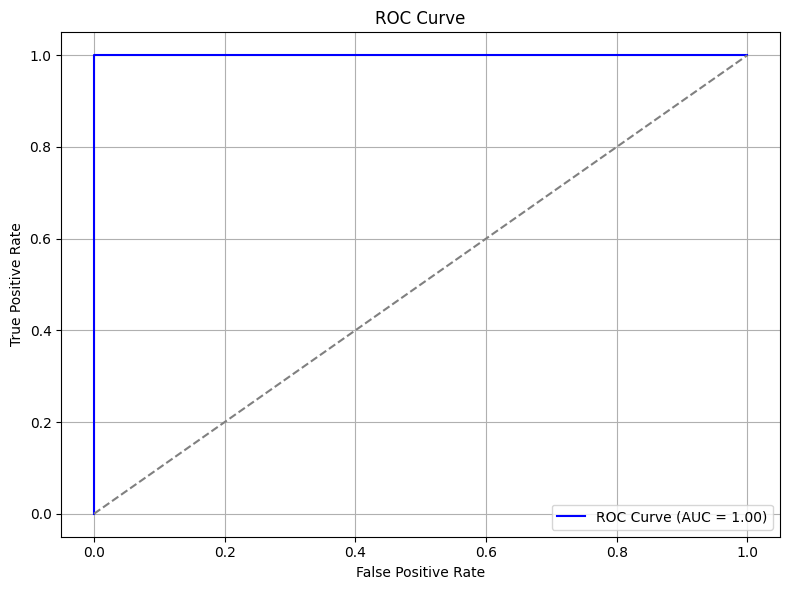

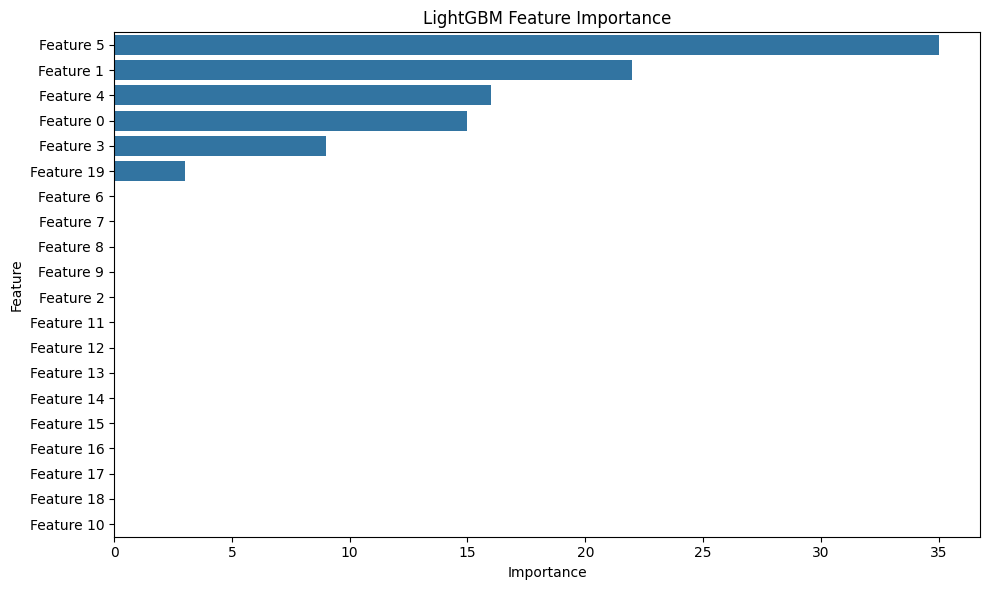

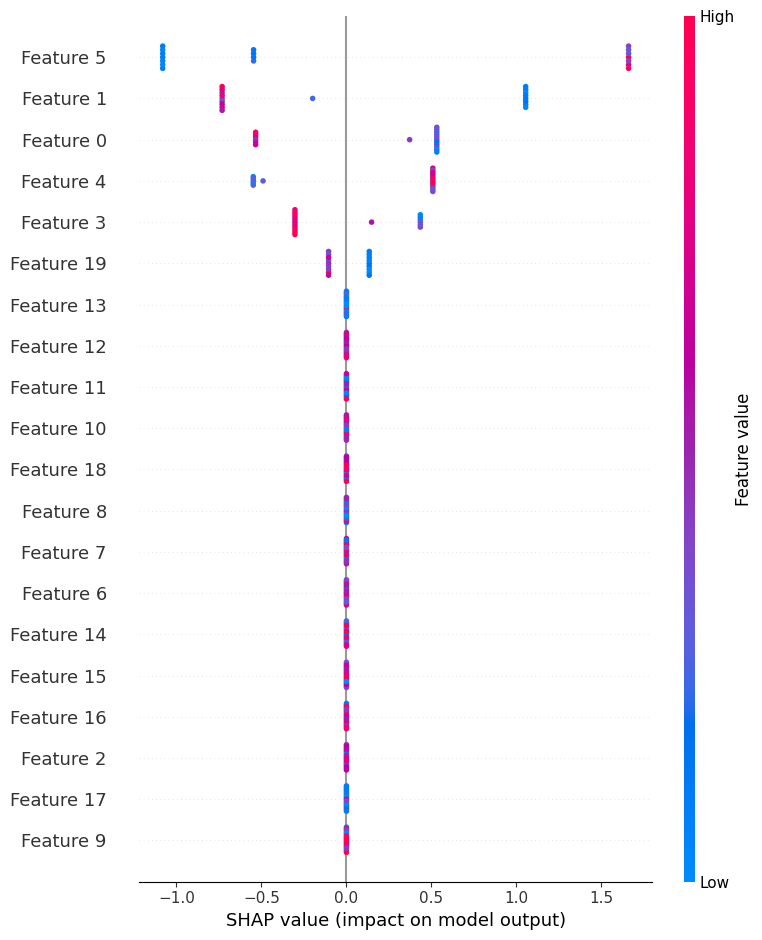

In [28]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.model_selection import StratifiedKFold
import pandas as pd
import shap

# Splitting dataset into training and testing sets
X = np.array(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

# Define the LightGBM classifier
lgbm_clf = lgb.LGBMClassifier(random_state=42)

# Define the hyperparameter grid for GridSearchCV
param_grid = {
    'num_leaves': [31, 50, 70],
    'max_depth': [5, 10, 15],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100, 200]
}

# Define Stratified K-Fold
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Use Stratified CV in GridSearch
grid_search = GridSearchCV(estimator=lgbm_clf,
                           param_grid=param_grid, 
                           cv=stratified_kfold,  # <- stratified split
                           scoring='accuracy', 
                           n_jobs=-1, 
                           verbose=1)

# Train the model using GridSearchCV
grid_search.fit(X_train, y_train)

# Output the best hyperparameters found by GridSearchCV
print("Best hyperparameters:", grid_search.best_params_)

# Predict on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]  # For ROC AUC

# Classification metrics
print("Classification Report:\n", classification_report(y_test, y_pred))

# Compute and print ROC AUC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

# Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Plot Feature Importance
feature_importance = best_model.feature_importances_

# Handle NumPy array by creating generic feature names
feature_names = [f"Feature {i}" for i in range(X.shape[1])]
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importance})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('LightGBM Feature Importance')
plt.tight_layout()
plt.show()

# Ensure X_test is a NumPy array and use the same feature names
X_test_array = np.array(X_test)

# Create SHAP explainer and compute SHAP values
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test_array)

# SHAP summary plot
shap.summary_plot(shap_values, X_test_array, feature_names=feature_names)
